In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
sns.set_style("whitegrid")
np.random.seed(42)
print("Imports OK")

Imports OK


In [20]:
customers    = pd.read_csv('Customers_list.csv')
products     = pd.read_csv('Products_list.csv')
transactions = pd.read_csv('Transactions_list.csv')

print("Customers:   ", customers.shape)
print("Products:    ", products.shape)
print("Transactions:", transactions.shape)

print("\n--- Customers head ---"); print(customers.head(3))
print("\n--- Products head ---");  print(products.head(3))
print("\n--- Transactions head ---"); print(transactions.head(3))

Customers:    (1000, 5)
Products:     (200, 6)
Transactions: (18829, 5)

--- Customers head ---
   CustomerID AgeGroup Region LoyaltyLevel  MembershipYears
0           1      50+  South       Bronze                8
1           2    26-35  South       Bronze                1
2           3    26-35   West       Bronze                2

--- Products head ---
   ProductID Category       Brand   Price  Rating  PopularityScore
0          1  Fitness  PrimeGoods   66.68    4.35                1
1          2  Kitchen     FitLife  367.01     NaN                2
2          3    Books     TechMax  176.00    4.57                1

--- Transactions head ---
   CustomerID  ProductID  PurchaseCount  LastPurchaseDays    Spend
0           1        171              1                82   462.89
1           2         48              4               255   433.60
2           2        112              3               315  1264.65


In [21]:
print("="*60)
print("DATA QUALITY – each dataset")
print("="*60)
for name, df in [("Customers", customers), ("Products", products), ("Transactions", transactions)]:
    print(f"\n--- {name} ---")
    print(f"Shape: {df.shape}")
    print(f"Missing values:\n{df.isnull().sum()[df.isnull().sum()>0]}")
    print(f"Duplicate rows: {df.duplicated().sum()}")
    print(f"Data types:\n{df.dtypes}")

DATA QUALITY – each dataset

--- Customers ---
Shape: (1000, 5)
Missing values:
Series([], dtype: int64)
Duplicate rows: 0
Data types:
CustomerID         int64
AgeGroup             str
Region               str
LoyaltyLevel         str
MembershipYears    int64
dtype: object

--- Products ---
Shape: (200, 6)
Missing values:
Rating    15
dtype: int64
Duplicate rows: 0
Data types:
ProductID            int64
Category               str
Brand                  str
Price              float64
Rating             float64
PopularityScore      int64
dtype: object

--- Transactions ---
Shape: (18829, 5)
Missing values:
Series([], dtype: int64)
Duplicate rows: 386
Data types:
CustomerID            int64
ProductID             int64
PurchaseCount         int64
LastPurchaseDays      int64
Spend               float64
dtype: object


In [22]:
# --- Standardise Category casing ---
print("Categories BEFORE:", products['Category'].unique())
products['Category'] = products['Category'].str.strip().str.title()
print("Categories AFTER: ", products['Category'].unique())

# --- Standardise Brand casing too (just in case) ---
products['Brand'] = products['Brand'].str.strip().str.title()

# --- Median impute missing Rating ---
rating_median = products['Rating'].median()
missing_ratings = products['Rating'].isnull().sum()
products['Rating'] = products['Rating'].fillna(rating_median)
print(f"\nFilled {missing_ratings} missing Ratings with median = {rating_median:.2f}")

# --- Ensure Price is numeric ---
products['Price'] = pd.to_numeric(products['Price'], errors='coerce')
print(f"\nMissing values remaining in Products: {products.isnull().sum().sum()}")

Categories BEFORE: <StringArray>
['Fitness', 'Kitchen', 'Books', 'Gaming', 'home', 'Home', 'fitness', 'Electronics', 'gaming', 'books', 'electronics', 'kitchen']
Length: 12, dtype: str
Categories AFTER:  <StringArray>
['Fitness', 'Kitchen', 'Books', 'Gaming', 'Home', 'Electronics']
Length: 6, dtype: str

Filled 15 missing Ratings with median = 3.87

Missing values remaining in Products: 0


In [23]:
# --- Merge transactions with product info ---
tx_full = transactions.merge(products, on='ProductID', how='left')
# --- Merge with customer info ---
tx_full = tx_full.merge(customers, on='CustomerID', how='left')

print("Merged transactions shape:", tx_full.shape)
print("Columns:", tx_full.columns.tolist())

# --- Integrity check: any unmatched rows? ---
print("\nMissing after merge:")
print(tx_full[['Category','Brand','Price','LoyaltyLevel','Region']].isnull().sum())

# --- Confirm referential integrity ---
print(f"\nTransactions with unknown ProductID: {(~transactions['ProductID'].isin(products['ProductID'])).sum()}")
print(f"Transactions with unknown CustomerID: {(~transactions['CustomerID'].isin(customers['CustomerID'])).sum()}")
print(f"Unique customers in tx: {transactions['CustomerID'].nunique()}")
print(f"Unique products in tx:  {transactions['ProductID'].nunique()}")

Merged transactions shape: (18829, 14)
Columns: ['CustomerID', 'ProductID', 'PurchaseCount', 'LastPurchaseDays', 'Spend', 'Category', 'Brand', 'Price', 'Rating', 'PopularityScore', 'AgeGroup', 'Region', 'LoyaltyLevel', 'MembershipYears']

Missing after merge:
Category        0
Brand           0
Price           0
LoyaltyLevel    0
Region          0
dtype: int64

Transactions with unknown ProductID: 0
Transactions with unknown CustomerID: 0
Unique customers in tx: 1000
Unique products in tx:  200


In [24]:
# --- Aggregate spend per (customer, product) ---
interactions = (transactions
    .groupby(['CustomerID','ProductID'])
    .agg(TotalSpend=('Spend','sum'),
         PurchaseCount=('PurchaseCount','sum'))
    .reset_index())

print("Interaction rows (unique customer-product pairs):", len(interactions))
print("Sparsity check:")
n_customers = interactions['CustomerID'].nunique()
n_products  = interactions['ProductID'].nunique()
n_possible  = n_customers * n_products
print(f"  Customers x Products = {n_customers} x {n_products} = {n_possible:,}")
print(f"  Actual interactions  = {len(interactions):,}")
print(f"  Sparsity             = {1 - len(interactions)/n_possible:.4%}")

# --- Pivot to customer-product matrix (values = TotalSpend) ---
matrix_spend = interactions.pivot_table(
    index='CustomerID', columns='ProductID', values='TotalSpend', fill_value=0
)
print(f"\nCustomer-Product matrix shape: {matrix_spend.shape}")
matrix_spend.head()

# Also a purchase-count matrix for the popularity method
matrix_count = interactions.pivot_table(
    index='CustomerID', columns='ProductID', values='PurchaseCount', fill_value=0
)

Interaction rows (unique customer-product pairs): 10263
Sparsity check:
  Customers x Products = 1000 x 200 = 200,000
  Actual interactions  = 10,263
  Sparsity             = 94.8685%

Customer-Product matrix shape: (1000, 200)


=== TOP 10 CUSTOMERS BY SPEND ===
   CustomerID  TotalSpend  N_Transactions  N_UniqueProducts LoyaltyLevel Region AgeGroup
0         481    24024.63              28                14       Silver  South    26-35
1         729    23828.03              29                15       Bronze   East    18-25
2          74    23815.67              30                17       Bronze  South    26-35
3         894    23626.75              27                13       Bronze  South      50+
4         660    23301.22              29                15       Bronze   West    36-50
5         902    22594.02              31                15       Bronze   West    36-50
6         544    22108.49              30                16       Bronze  South    26-35
7          83    21968.20              29                17         Gold   West    26-35
8         456    21912.71              28                13       Bronze  South    18-25
9         576    21776.83              29                15       Bronze   E

C:\Users\Kiero\AppData\Local\Temp\ipykernel_24408\2526625680.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_spend, x='CustomerID', y='TotalSpend', ax=ax, palette='Blues_d')


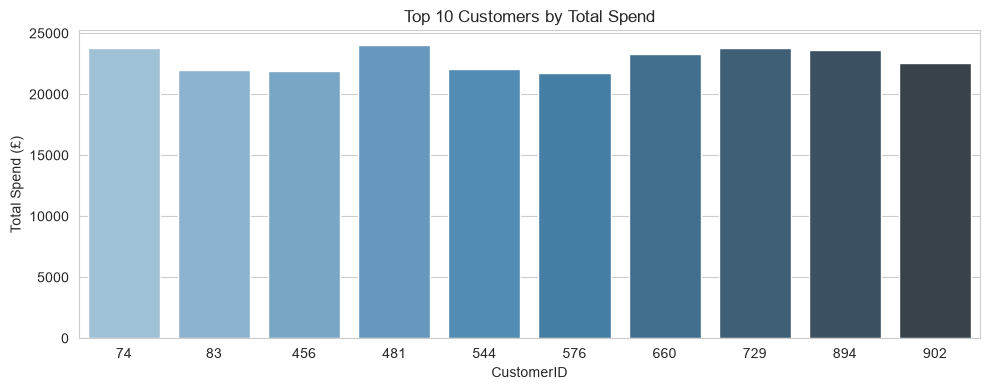

In [25]:
customer_spend = (tx_full.groupby('CustomerID')
    .agg(TotalSpend=('Spend','sum'),
         N_Transactions=('ProductID','count'),
         N_UniqueProducts=('ProductID','nunique'))
    .reset_index()
    .sort_values('TotalSpend', ascending=False))

print("=== TOP 10 CUSTOMERS BY SPEND ===")
top10_spend = customer_spend.head(10).merge(customers, on='CustomerID')
print(top10_spend[['CustomerID','TotalSpend','N_Transactions',
                   'N_UniqueProducts','LoyaltyLevel','Region','AgeGroup']])

fig, ax = plt.subplots(figsize=(10,4))
sns.barplot(data=top10_spend, x='CustomerID', y='TotalSpend', ax=ax, palette='Blues_d')
ax.set_title('Top 10 Customers by Total Spend')
ax.set_xlabel('CustomerID'); ax.set_ylabel('Total Spend (£)')
plt.tight_layout(); plt.show()

=== TOP 10 CUSTOMERS BY PURCHASE FREQUENCY ===
   CustomerID  TotalPurchases  N_Transactions LoyaltyLevel Region
0         450              87              30       Bronze  South
1         880              87              31       Silver   West
2          74              86              30       Bronze  South
3         374              85              30       Bronze  South
4         811              85              31       Silver   West
5         168              84              31       Silver   West
6         329              83              27       Silver  North
7         298              82              29       Bronze   East
8         812              82              29       Bronze  South
9         240              81              29       Bronze   East


C:\Users\Kiero\AppData\Local\Temp\ipykernel_24408\163834505.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_freq, x='CustomerID', y='TotalPurchases', ax=ax, palette='Greens_d')


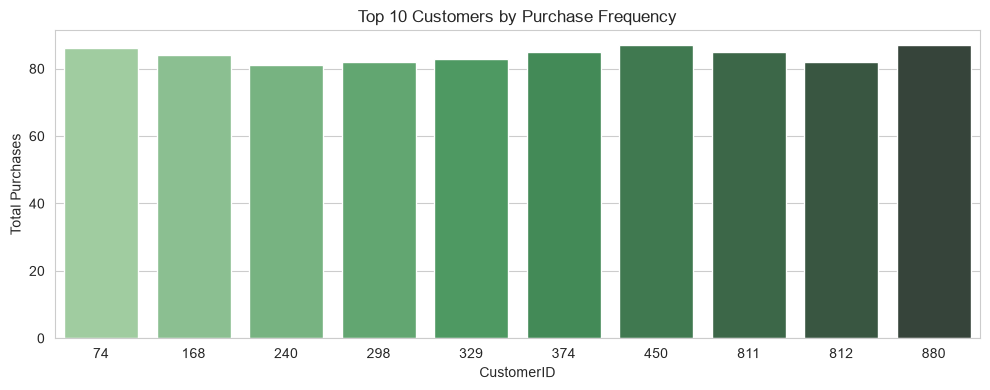

In [26]:
freq = (tx_full.groupby('CustomerID')
    .agg(TotalPurchases=('PurchaseCount','sum'),
         N_Transactions=('ProductID','count'))
    .reset_index()
    .sort_values('TotalPurchases', ascending=False))

print("=== TOP 10 CUSTOMERS BY PURCHASE FREQUENCY ===")
top10_freq = freq.head(10).merge(customers, on='CustomerID')
print(top10_freq[['CustomerID','TotalPurchases','N_Transactions','LoyaltyLevel','Region']])

fig, ax = plt.subplots(figsize=(10,4))
sns.barplot(data=top10_freq, x='CustomerID', y='TotalPurchases', ax=ax, palette='Greens_d')
ax.set_title('Top 10 Customers by Purchase Frequency')
ax.set_xlabel('CustomerID'); ax.set_ylabel('Total Purchases')
plt.tight_layout(); plt.show()

=== CUSTOMER VALUE BY LOYALTY LEVEL ===
              N_Customers  AvgSpend  MedianSpend  TotalSpend  AvgTransactions
LoyaltyLevel                                                                 
Gold                  187  11477.92     11716.20  2146370.31            19.14
Silver                320  11404.52     11446.04  3649446.67            19.01
Bronze                493  11241.15     11326.61  5541886.64            18.59

Total revenue: £11,337,703.62
Top 10% of customers generate: 17.1% of revenue


C:\Users\Kiero\AppData\Local\Temp\ipykernel_24408\3134870020.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=loyalty_value.index, y=loyalty_value['AvgSpend'], ax=ax, palette='Oranges_d')


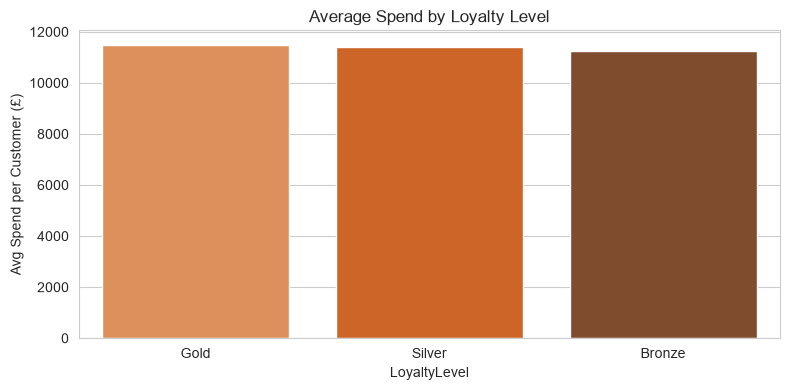

In [27]:
# Compute each customer's spend and merge loyalty tier
cv = customer_spend.merge(customers[['CustomerID','LoyaltyLevel']], on='CustomerID', how='left')

# Segment by LoyaltyLevel
loyalty_value = cv.groupby('LoyaltyLevel').agg(
    N_Customers=('CustomerID','count'),
    AvgSpend=('TotalSpend','mean'),
    MedianSpend=('TotalSpend','median'),
    TotalSpend=('TotalSpend','sum'),
    AvgTransactions=('N_Transactions','mean')
).round(2).sort_values('AvgSpend', ascending=False)

print("=== CUSTOMER VALUE BY LOYALTY LEVEL ===")
print(loyalty_value)
print(f"\nTotal revenue: £{cv['TotalSpend'].sum():,.2f}")
print(f"Top 10% of customers generate: "
      f"{cv.nlargest(max(1,int(len(cv)*0.1)), 'TotalSpend')['TotalSpend'].sum() / cv['TotalSpend'].sum():.1%} of revenue")

fig, ax = plt.subplots(figsize=(8,4))
sns.barplot(x=loyalty_value.index, y=loyalty_value['AvgSpend'], ax=ax, palette='Oranges_d')
ax.set_title('Average Spend by Loyalty Level')
ax.set_ylabel('Avg Spend per Customer (£)')
plt.tight_layout(); plt.show()

=== TOP 10 PRODUCTS BY REVENUE ===
 ProductID Category      Brand   Revenue  UnitsSold  N_Customers  AvgRating
        64    Books Primegoods 994281.44       5981          183       5.00
        76  Kitchen    Fitlife 527445.35       2435          177       4.26
        73   Gaming    Techmax 523635.33       1061          160       3.87
       137  Fitness    Nextgen 383666.22       1471          166       4.08
        18   Gaming   Smartbuy 295219.86        622          114       3.76
        47   Gaming    Nextgen 293518.26        639          125       4.60
        12  Fitness Primegoods 276865.40       2380          189       2.61
         6  Kitchen   Smartbuy 218411.18        698          136       4.31
        19  Kitchen Primegoods 207303.55        485          117       4.13
        44   Gaming    Techmax 204778.64       1067          150       4.72


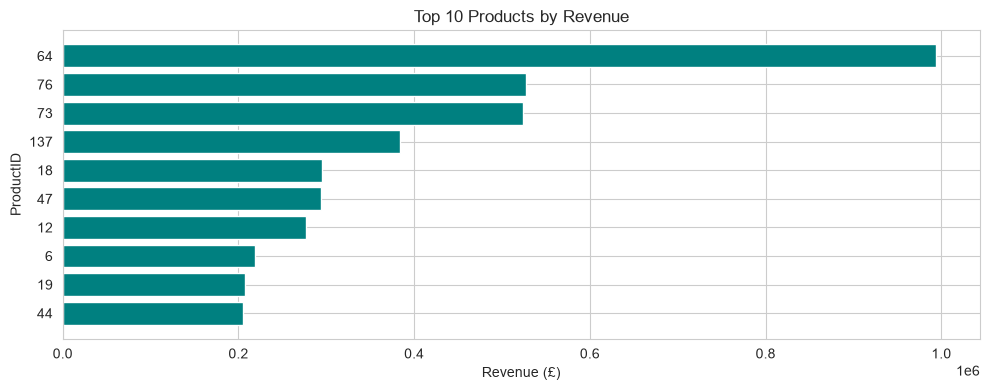

In [28]:
product_perf = (tx_full.groupby(['ProductID','Category','Brand'])
    .agg(Revenue=('Spend','sum'),
         UnitsSold=('PurchaseCount','sum'),
         N_Customers=('CustomerID','nunique'),
         AvgRating=('Rating','mean'))
    .reset_index()
    .sort_values('Revenue', ascending=False))

print("=== TOP 10 PRODUCTS BY REVENUE ===")
print(product_perf.head(10).round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(10,4))
top10_products = product_perf.head(10)
ax.barh(top10_products['ProductID'].astype(str), top10_products['Revenue'], color='teal')
ax.invert_yaxis()
ax.set_title('Top 10 Products by Revenue')
ax.set_xlabel('Revenue (£)'); ax.set_ylabel('ProductID')
plt.tight_layout(); plt.show()

=== REVENUE BY CATEGORY ===
                Revenue  UnitsSold  N_Customers  N_Products
Category                                                   
Books        2398961.54      11143          861          35
Gaming       2336484.84       7487          800          27
Kitchen      1914469.26       7329          770          35
Fitness      1856035.29       9046          789          38
Electronics  1472920.12       5666          841          32
Home         1358832.57       6229          760          33


C:\Users\Kiero\AppData\Local\Temp\ipykernel_24408\2351150393.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_perf.index, y=cat_perf['Revenue'], ax=axes[0], palette='Purples_d')
C:\Users\Kiero\AppData\Local\Temp\ipykernel_24408\2351150393.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_perf.index, y=cat_perf['UnitsSold'], ax=axes[1], palette='Oranges_d')


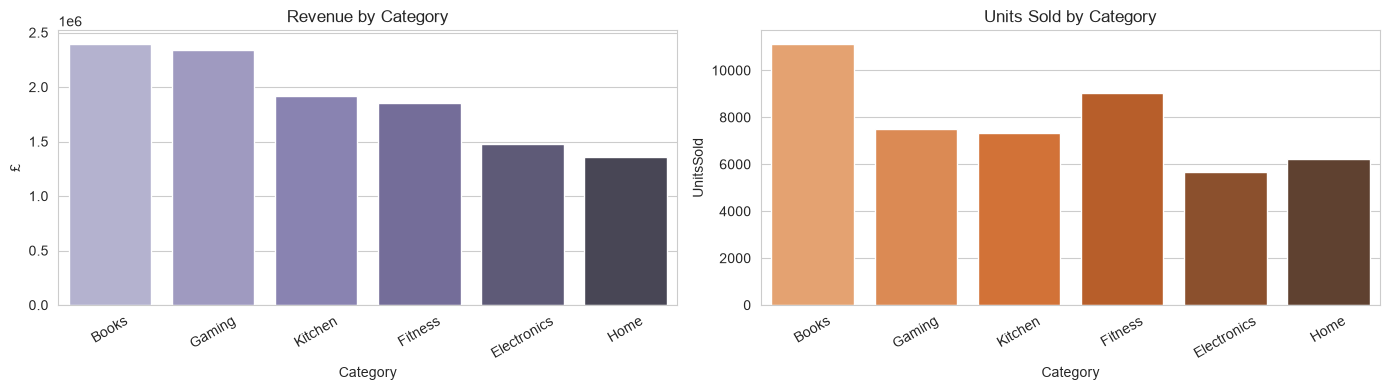

In [29]:
cat_perf = (tx_full.groupby('Category')
    .agg(Revenue=('Spend','sum'),
         UnitsSold=('PurchaseCount','sum'),
         N_Customers=('CustomerID','nunique'),
         N_Products=('ProductID','nunique'))
    .round(2).sort_values('Revenue', ascending=False))

print("=== REVENUE BY CATEGORY ===")
print(cat_perf)

fig, axes = plt.subplots(1, 2, figsize=(14,4))
sns.barplot(x=cat_perf.index, y=cat_perf['Revenue'], ax=axes[0], palette='Purples_d')
axes[0].set_title('Revenue by Category'); axes[0].set_ylabel('£')
axes[0].tick_params(axis='x', rotation=30)

sns.barplot(x=cat_perf.index, y=cat_perf['UnitsSold'], ax=axes[1], palette='Oranges_d')
axes[1].set_title('Units Sold by Category')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

=== REVENUE BY BRAND ===
               Revenue  UnitsSold  N_Customers  N_Products
Brand                                                     
Techmax     2672531.51      10445          913          45
Primegoods  2508364.49      14303          882          33
Fitlife     1747949.61       6795          657          34
Nextgen     1570724.41       5670          741          27
Smartbuy    1461372.05       5000          765          29
Homepro     1376761.55       4687          714          32


C:\Users\Kiero\AppData\Local\Temp\ipykernel_24408\2184512720.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=brand_perf.index, y=brand_perf['Revenue'], ax=ax, palette='Blues_d')


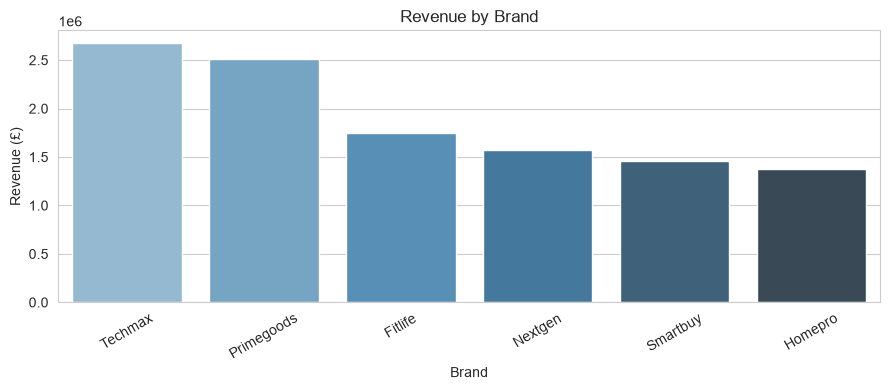

In [30]:
brand_perf = (tx_full.groupby('Brand')
    .agg(Revenue=('Spend','sum'),
         UnitsSold=('PurchaseCount','sum'),
         N_Customers=('CustomerID','nunique'),
         N_Products=('ProductID','nunique'))
    .round(2).sort_values('Revenue', ascending=False))

print("=== REVENUE BY BRAND ===")
print(brand_perf)

fig, ax = plt.subplots(figsize=(9,4))
sns.barplot(x=brand_perf.index, y=brand_perf['Revenue'], ax=ax, palette='Blues_d')
ax.set_title('Revenue by Brand'); ax.set_ylabel('Revenue (£)')
plt.xticks(rotation=30)
plt.tight_layout(); plt.show()

In [31]:
region_perf = (tx_full.groupby('Region')
    .agg(TotalRevenue=('Spend','sum'),
         AvgSpendPerTx=('Spend','mean'),
         N_Customers=('CustomerID','nunique'),
         N_Transactions=('ProductID','count'))
    .round(2).sort_values('TotalRevenue', ascending=False))

print("=== GROUPBY 1: Revenue by Customer Region ===")
print(region_perf)

=== GROUPBY 1: Revenue by Customer Region ===
        TotalRevenue  AvgSpendPerTx  N_Customers  N_Transactions
Region                                                          
South     2989799.24         598.08          261            4999
West      2906385.70         607.14          252            4787
North     2797853.59         592.64          247            4721
East      2643665.09         611.68          240            4322


=== GROUPBY 2: Revenue by Age Group ===
          TotalRevenue  AvgSpendPerTx  N_Customers  N_Transactions
AgeGroup                                                          
26-35       2994769.35         608.32          267            4923
36-50       2848070.82         608.04          251            4684
18-25       2841081.69         597.62          245            4754
50+         2653781.76         593.95          237            4468


C:\Users\Kiero\AppData\Local\Temp\ipykernel_24408\3142556078.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=age_perf.index, y=age_perf['TotalRevenue'], ax=ax, palette='Greens_d')


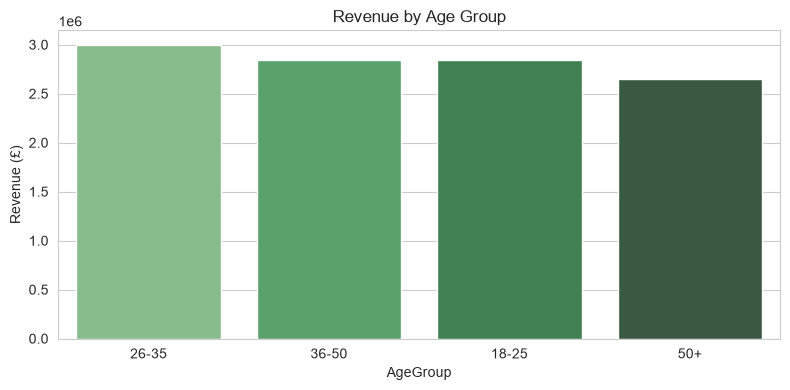

In [32]:
age_perf = (tx_full.groupby('AgeGroup')
    .agg(TotalRevenue=('Spend','sum'),
         AvgSpendPerTx=('Spend','mean'),
         N_Customers=('CustomerID','nunique'),
         N_Transactions=('ProductID','count'))
    .round(2).sort_values('TotalRevenue', ascending=False))

print("=== GROUPBY 2: Revenue by Age Group ===")
print(age_perf)

fig, ax = plt.subplots(figsize=(8,4))
sns.barplot(x=age_perf.index, y=age_perf['TotalRevenue'], ax=ax, palette='Greens_d')
ax.set_title('Revenue by Age Group'); ax.set_ylabel('Revenue (£)')
plt.tight_layout(); plt.show()

In [33]:
loyalty_cat = (tx_full.groupby(['LoyaltyLevel','Category'])
    .agg(TotalSpend=('Spend','sum'),
         AvgSpendPerTx=('Spend','mean'),
         N_Transactions=('ProductID','count'))
    .round(2).reset_index())

print("=== GROUPBY 3: Spend by Loyalty Level × Category ===")
print(loyalty_cat.sort_values(['LoyaltyLevel','TotalSpend'],
                              ascending=[True, False]).to_string(index=False))

=== GROUPBY 3: Spend by Loyalty Level × Category ===
LoyaltyLevel    Category  TotalSpend  AvgSpendPerTx  N_Transactions
      Bronze       Books  1192924.96         540.27            2208
      Bronze      Gaming  1152981.22         792.43            1455
      Bronze     Kitchen   948596.91         651.96            1455
      Bronze     Fitness   915652.04         502.83            1821
      Bronze Electronics   674839.72         642.09            1051
      Bronze        Home   656891.79         558.11            1177
        Gold      Gaming   471264.88         825.33             571
        Gold       Books   418258.08         541.08             773
        Gold     Kitchen   350383.72         631.32             555
        Gold     Fitness   337809.27         502.69             672
        Gold Electronics   295350.87         647.70             456
        Gold        Home   273303.49         495.12             552
      Silver       Books   787778.50         534.81            

=== PIVOT 1: Revenue by Category × Loyalty Level ===
LoyaltyLevel      Bronze       Gold     Silver
Category                                      
Books         1192924.96  418258.08  787778.50
Electronics    674839.72  295350.87  502729.53
Fitness        915652.04  337809.27  602573.98
Gaming        1152981.22  471264.88  712238.74
Home           656891.79  273303.49  428637.29
Kitchen        948596.91  350383.72  615488.63


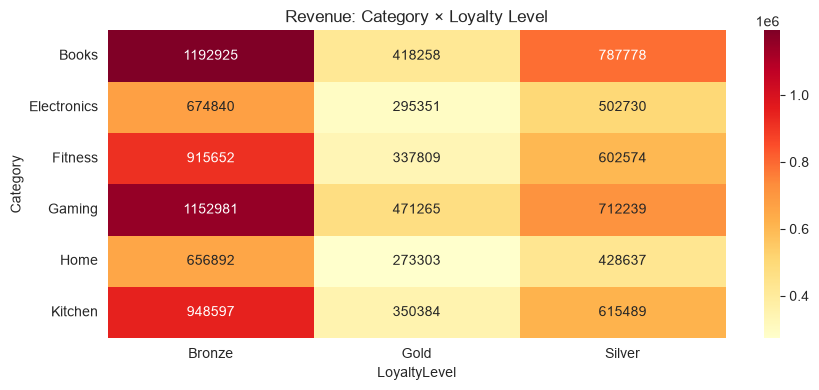

In [34]:
pivot1 = pd.pivot_table(
    tx_full, values='Spend',
    index='Category', columns='LoyaltyLevel',
    aggfunc='sum'
).round(2)

print("=== PIVOT 1: Revenue by Category × Loyalty Level ===")
print(pivot1)

plt.figure(figsize=(9,4))
sns.heatmap(pivot1, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Revenue: Category × Loyalty Level')
plt.tight_layout(); plt.show()

=== PIVOT 2: Revenue by Brand × Age Group ===
AgeGroup        18-25      26-35      36-50        50+
Brand                                                 
Fitlife     459754.45  445841.03  425341.16  417012.97
Homepro     336636.51  366040.85  360624.24  313459.95
Nextgen     387814.14  408958.19  411100.53  362851.55
Primegoods  646743.72  683387.90  595820.29  582412.58
Smartbuy    365597.55  385609.86  365807.34  344357.30
Techmax     644535.32  704931.52  689377.26  633687.41


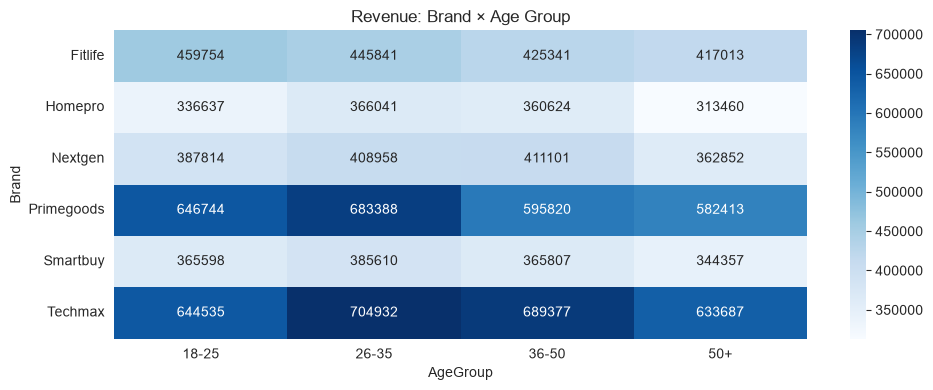

In [35]:
pivot2 = pd.pivot_table(
    tx_full, values='Spend',
    index='Brand', columns='AgeGroup',
    aggfunc='sum'
).round(2)

print("=== PIVOT 2: Revenue by Brand × Age Group ===")
print(pivot2)

plt.figure(figsize=(10,4))
sns.heatmap(pivot2, annot=True, fmt='.0f', cmap='Blues')
plt.title('Revenue: Brand × Age Group')
plt.tight_layout(); plt.show()

In [36]:
# --- Product popularity: total revenue + units sold ---
popularity = (tx_full.groupby(['ProductID','Category','Brand','Price'])
    .agg(TotalRevenue=('Spend','sum'),
         UnitsSold=('PurchaseCount','sum'),
         N_Customers=('CustomerID','nunique'))
    .reset_index()
    .sort_values('TotalRevenue', ascending=False))

print("Top 10 products (popularity baseline):")
print(popularity.head(10).round(2).to_string(index=False))

# --- Popularity recommender: returns top-N products overall ---
def popularity_recommender(n=10, exclude_ids=None):
    """Recommend the top-N most popular products (by total revenue).
       exclude_ids: list of product IDs already bought (optional)."""
    recs = popularity.copy()
    if exclude_ids:
        recs = recs[~recs['ProductID'].isin(exclude_ids)]
    return recs.head(n)[['ProductID','Category','Brand','TotalRevenue']].reset_index(drop=True)

print("\n=== GLOBAL TOP 10 RECOMMENDATIONS (Popularity) ===")
print(popularity_recommender(10).to_string(index=False))

# Example for a specific customer: exclude their purchase history
example_customer = 5  # pick any CustomerID
bought = transactions[transactions['CustomerID'] == example_customer]['ProductID'].tolist()
print(f"\nCustomer {example_customer} already bought {len(bought)} products.")
print("Top 5 NEW recommendations (Popularity, excluding bought):")
print(popularity_recommender(5, exclude_ids=bought).to_string(index=False))

Top 10 products (popularity baseline):
 ProductID Category      Brand  Price  TotalRevenue  UnitsSold  N_Customers
        64    Books Primegoods 180.13     994281.44       5981          183
        76  Kitchen    Fitlife  20.70     527445.35       2435          177
        73   Gaming    Techmax 415.14     523635.33       1061          160
       137  Fitness    Nextgen  24.58     383666.22       1471          166
        18   Gaming   Smartbuy 179.41     295219.86        622          114
        47   Gaming    Nextgen 116.36     293518.26        639          125
        12  Fitness Primegoods 422.56     276865.40       2380          189
         6  Kitchen   Smartbuy 359.14     218411.18        698          136
        19  Kitchen Primegoods 225.84     207303.55        485          117
        44   Gaming    Techmax 136.66     204778.64       1067          150

=== GLOBAL TOP 10 RECOMMENDATIONS (Popularity) ===
 ProductID Category      Brand  TotalRevenue
        64    Books Primegoo

In [37]:
# Use the purchase-count matrix built earlier (customers x products)
# Compute cosine similarity between PRODUCTS (columns of the matrix)
product_matrix = matrix_count.T  # shape (n_products, n_customers)

# Cosine similarity between products (rows = products, columns = customers)
item_sim = cosine_similarity(product_matrix)
item_sim_df = pd.DataFrame(item_sim,
                            index=product_matrix.index,
                            columns=product_matrix.index)

print("Item-Item similarity matrix shape:", item_sim_df.shape)
print("\nSample: similarity of first 5 products to themselves and each other:")
print(item_sim_df.iloc[:5, :5].round(3))

Item-Item similarity matrix shape: (200, 200)

Sample: similarity of first 5 products to themselves and each other:
ProductID    1      2    3      4    5
ProductID                             
1          1.0  0.000  0.0  0.000  0.0
2          0.0  1.000  0.0  0.303  0.0
3          0.0  0.000  1.0  0.000  0.0
4          0.0  0.303  0.0  1.000  0.0
5          0.0  0.000  0.0  0.000  1.0


In [38]:
def item_based_recommender(customer_id, n=10):
    """Recommend n products to a customer based on the cosine-similarity
       of products they already bought."""
    # Products this customer has interacted with
    user_items = matrix_count.loc[customer_id]
    user_items = user_items[user_items > 0].index.tolist()

    if not user_items:
        return pd.DataFrame(columns=['ProductID','Score'])

    # Sum similarity scores across all bought products -> candidate scores
    scores = item_sim_df.loc[user_items].sum(axis=0)

    # Exclude products the user already bought
    scores = scores.drop(user_items, errors='ignore')

    # Sort descending
    top_n = scores.sort_values(ascending=False).head(n).round(3)

    # Attach product metadata
    rec = top_n.reset_index()
    rec.columns = ['ProductID', 'SimilarityScore']
    rec = rec.merge(products[['ProductID','Category','Brand','Price','Rating']],
                    on='ProductID', how='left')
    return rec

# Test on a few example customers
for cid in [5, 52, 53, 54, 56]:
    bought = matrix_count.loc[cid]
    bought = bought[bought > 0]
    print(f"\n=== Customer {cid} — bought {len(bought)} unique products ===")
    print("Top 5 item-based recommendations:")
    print(item_based_recommender(cid, n=5).to_string(index=False))


=== Customer 5 — bought 1 unique products ===
Top 5 item-based recommendations:
 ProductID  SimilarityScore Category      Brand  Price  Rating
        12            0.640  Fitness Primegoods 422.56    2.61
       110            0.527  Kitchen   Smartbuy  46.70    4.37
        75            0.505    Books    Homepro  33.47    3.32
       164            0.490    Books    Techmax 177.93    3.26
        23            0.470   Gaming Primegoods 190.48    2.73

=== Customer 52 — bought 7 unique products ===
Top 5 item-based recommendations:
 ProductID  SimilarityScore Category      Brand  Price  Rating
         6            2.737  Kitchen   Smartbuy 359.14    4.31
        75            2.500    Books    Homepro  33.47    3.32
        23            2.259   Gaming Primegoods 190.48    2.73
         9            2.226     Home    Homepro  21.72    3.11
        56            2.144   Gaming    Fitlife 351.52    3.17

=== Customer 53 — bought 13 unique products ===
Top 5 item-based recommendations

In [39]:
example_customers = [5, 52, 53, 54, 56]

for cid in example_customers:
    bought = matrix_count.loc[cid]; bought = bought[bought > 0]
    print("="*65)
    print(f"CUSTOMER {cid}  |  {len(bought)} unique products bought  |  "
          f"loyalty: {customers.loc[customers.CustomerID==cid,'LoyaltyLevel'].iloc[0]}")
    print("-"*65)

    print("\n--- POPULARITY-based (top 5 excluding bought) ---")
    print(popularity_recommender(5, exclude_ids=bought.index.tolist()).to_string(index=False))

    print("\n--- ITEM-BASED collaborative filtering (top 5) ---")
    print(item_based_recommender(cid, n=5).to_string(index=False))
    print()

CUSTOMER 5  |  1 unique products bought  |  loyalty: Bronze
-----------------------------------------------------------------

--- POPULARITY-based (top 5 excluding bought) ---
 ProductID Category      Brand  TotalRevenue
        64    Books Primegoods     994281.44
        76  Kitchen    Fitlife     527445.35
        73   Gaming    Techmax     523635.33
       137  Fitness    Nextgen     383666.22
        18   Gaming   Smartbuy     295219.86

--- ITEM-BASED collaborative filtering (top 5) ---
 ProductID  SimilarityScore Category      Brand  Price  Rating
        12            0.640  Fitness Primegoods 422.56    2.61
       110            0.527  Kitchen   Smartbuy  46.70    4.37
        75            0.505    Books    Homepro  33.47    3.32
       164            0.490    Books    Techmax 177.93    3.26
        23            0.470   Gaming Primegoods 190.48    2.73

CUSTOMER 52  |  7 unique products bought  |  loyalty: Gold
---------------------------------------------------------------

In [ ]:
# Metrics:
# 1) Personalisation — do recommendations differ per customer?
# 2) Category diversity — do recs span multiple categories?
# 3) Cold-start coverage — what % of customers can each method serve?

popularity_categories = set(popularity.head(20)['Category'].unique())
print(f"Popularity recommender serves 100% of customers (no history needed).")
print(f"Popularity top-20 categories covered: {popularity_categories}")

# Personalisation check: do item-based recs differ per user?
def rec_set(cid, n=10):
    return set(item_based_recommender(cid, n)['ProductID'].tolist())

pairwise = {}
sample_users = example_customers
for i, u1 in enumerate(sample_users):
    for u2 in sample_users[i+1:]:
        overlap = len(rec_set(u1) & rec_set(u2))
        pairwise[(u1,u2)] = overlap

print("\nOverlap between item-based recs for different users (should be low):")
for pair, o in pairwise.items():
    print(f"  {pair}: {o} shared products out of 10")

# Category diversity of item-based recommendations
for cid in example_customers:
    recs = item_based_recommender(cid, n=10)
    print(f"\nCustomer {cid} item-based recs — unique categories: {recs['Category'].nunique()}")

# Cold start: how many products have enough signal?
n_products_in_tx = transactions['ProductID'].nunique()
n_products_total = len(products)
print(f"\nProducts with any transactions: {n_products_in_tx} / {n_products_total} "
      f"({n_products_in_tx/n_products_total:.1%})")
print(f"Products with no data (popularity-only fallback needed): "
      f"{n_products_total - n_products_in_tx}")

In [40]:
comparison = pd.DataFrame([
    {'Criterion': 'Personalisation',
     'Popularity-based': 'None — same for all users',
     'Item-Based CF': 'High — differs per user based on history'},
    {'Criterion': 'Cold-start customers',
     'Popularity-based': 'Works — no history required',
     'Item-Based CF': 'Fails — falls back to popularity'},
    {'Criterion': 'Cold-start products',
     'Popularity-based': 'Fails — needs prior sales',
     'Item-Based CF': 'Works if similar products exist'},
    {'Criterion': 'Compute cost',
     'Popularity-based': 'Very low (one sort)',
     'Item-Based CF': 'Moderate (n_products² similarity)'},
    {'Criterion': 'Interpretability',
     'Popularity-based': 'Trivial',
     'Item-Based CF': 'Medium — "because you bought X"'},
    {'Criterion': 'Business use case',
     'Popularity-based': 'Homepage / new visitors',
     'Item-Based CF': 'Logged-in users / product page "You may also like"'},
])

print("=== RECOMMENDATION APPROACH COMPARISON ===")
print(comparison.to_string(index=False))

=== RECOMMENDATION APPROACH COMPARISON ===
           Criterion            Popularity-based                                      Item-Based CF
     Personalisation   None — same for all users           High — differs per user based on history
Cold-start customers Works — no history required                   Fails — falls back to popularity
 Cold-start products   Fails — needs prior sales                    Works if similar products exist
        Compute cost         Very low (one sort)                  Moderate (n_products² similarity)
    Interpretability                     Trivial                    Medium — "because you bought X"
   Business use case     Homepage / new visitors Logged-in users / product page "You may also like"


In [41]:
print("="*65)
print("KEY FINDINGS FOR TASK 3 (Business Interpretation)")
print("="*65)

# Save summary to a CSV for reuse in your write-up
summary = {
    'Total Revenue': f"£{tx_full['Spend'].sum():,.2f}",
    'Unique Customers': customers['CustomerID'].nunique(),
    'Unique Products Sold': transactions['ProductID'].nunique(),
    'Top 10% customers revenue share':
        f"{cv.nlargest(max(1,int(len(cv)*0.1)), 'TotalSpend')['TotalSpend'].sum() / cv['TotalSpend'].sum():.1%}",
    'Top category by revenue': cat_perf.index[0],
    'Top category revenue': f"£{cat_perf.iloc[0]['Revenue']:,.2f}",
    'Top brand by revenue': brand_perf.index[0],
    'Top product by revenue': f"Product {product_perf.iloc[0]['ProductID']} (£{product_perf.iloc[0]['Revenue']:,.2f})",
    'Best recommender choice': 'Item-Based CF for logged-in users; Popularity as fallback',
}

for k, v in summary.items():
    print(f"{k:40s}: {v}")

# Save both dataframes for later use
popularity.to_csv('popularity_scores.csv', index=False)
customer_spend.to_csv('customer_spend.csv', index=False)
product_perf.to_csv('product_performance.csv', index=False)
print("\nSaved popularity_scores.csv, customer_spend.csv, product_performance.csv")

KEY FINDINGS FOR TASK 3 (Business Interpretation)
Total Revenue                           : £11,337,703.62
Unique Customers                        : 1000
Unique Products Sold                    : 200
Top 10% customers revenue share         : 17.1%
Top category by revenue                 : Books
Top category revenue                    : £2,398,961.54
Top brand by revenue                    : Techmax
Top product by revenue                  : Product 64 (£994,281.44)
Best recommender choice                 : Item-Based CF for logged-in users; Popularity as fallback

Saved popularity_scores.csv, customer_spend.csv, product_performance.csv
